<a href="https://colab.research.google.com/github/Shemuel-bot/AI-ball-notebooks/blob/main/ai_ball_profiled_hash_search_fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Ball — Local, Slot-Conditioned Hash Search

This version keeps the machine **single-stage**: each ball still performs exactly one
hash lookup and then reads the emitted string from the deflector table.

The training hash is changed to make generalization possible without layering:

- **Locality:** a ball's address depends only on a configurable neighborhood around it.
- **Relative-position sharing:** the same `(relative offset, token)` feature reuses one
  hash coefficient at every absolute position.
- **Slot separation:** each ball position gets its own bucket region, so a digit emitted
  by one output slot cannot collide with a different slot's meaning.
- **Reuse-aware search:** primary class-purity/CE remains the objective; ties prefer using
  the same class/bucket pair repeatedly instead of creating fresh buckets.
- **Multi-start training:** several independent discrete searches are tried and the best
  training solution is kept.

The physical simulator is unchanged in spirit: `travel -> one lookup -> walk`.
No input-reading layers are added.


In [ ]:
try:
    import datasets
except ImportError:
    !pip install -q datasets
    import datasets

import random

def stream_tinystories_cases(n_cases, max_window_len=500, min_window_len=5):
    """Stream TinyStories dataset and yield training/testing cases with random length sub-strings."""
    print("Connecting to Hugging Face to stream 'roneneldan/TinyStories'... ")
    dataset = datasets.load_dataset('roneneldan/TinyStories', split='train', streaming=True)

    cases = []
    iterator = iter(dataset)

    while len(cases) < n_cases:
        try:
            story = next(iterator)['text']

            # Sample a random context length between the minimum and maximum constraints
            window_len = random.randint(min_window_len, max_window_len)
            if len(story) <= window_len + 1:
                continue

            # Extract a random window of the sampled length + 1 target character
            start_idx = random.randint(0, len(story) - window_len - 1)
            inp = story[start_idx : start_idx + window_len]
            target = story[start_idx + window_len]

            if (inp, target) not in cases:
                cases.append((inp, target))
        except StopIteration:
            break

    return cases

# Configure and stream the data with dynamic context lengths
STREAM_N_CASES = 100000  # Adjust as needed
tiny_cases = stream_tinystories_cases(STREAM_N_CASES, max_window_len=100, min_window_len=5)
print(f"Streamed {len(tiny_cases)} cases successfully!")
print("Sample Case Input:\n", repr(tiny_cases[0][0]))
print("Sample Case Target:\n", repr(tiny_cases[0][1]))

Connecting to Hugging Face to stream 'roneneldan/TinyStories'... 
Streamed 100000 cases successfully!
Sample Case Input:
 'p. Lily wanted to share the needle with her mom, so she could sew a button on her sh'
Sample Case Target:
 'i'


In [ ]:
import random, time, math, difflib
import numpy as np

CFG = dict(
    local_D=300,             # buckets per ball/output slot
    hash_radius=1,       # local neighborhood radius in token positions
    direction_range=60,     # learned feature offsets are searched in [-V, V]
    bounce=10,
    cap=10,
    n_cases=5000, train_share=0.8, seed=66,
    loss='ce',              # 'hard' or 'ce'
    reuse_tiebreak=0.01,    # secondary preference when primary loss ties
    restarts=1,              # independent discrete initializations
    rounds=1,
    sweeps=1,
    ntry=12,
)
random.seed(CFG['seed']); np.random.seed(CFG['seed'])


## Data: tokenizer and arithmetic generalization test

The training task is deliberately structured: `1+i=` -> `i+1`.
The train/test split is by **exact context**, while every test token is drawn from the
same small alphabet. This isolates whether the hash learns reusable structure.


In [ ]:
def TokenizeInput(input, alphabet):
    """Greedy non-overlapping tokenization: earliest start, then longest, then alphabet order."""
    input_str = str(input)
    matches = []
    for order, item in enumerate(alphabet):
        item_str = str(item)
        if not item_str:
            continue
        start_pos = 0
        while True:
            index = input_str.find(item_str, start_pos)
            if index == -1:
                break
            matches.append((index, -len(item_str), order, item))
            start_pos = index + 1
    matches.sort(key=lambda m: (m[0], m[1], m[2]))
    out, last_end = [], 0
    for index, neg_len, _, item in matches:
        if index >= last_end:
            out.append(item)
            last_end = index - neg_len
    return out

# Extract the unique alphabet characters present across all TinyStories inputs
alphabet = sorted(list(set(char for inp, _ in tiny_cases for char in inp)))

output = sorted(set(ch for _, t in tiny_cases for ch in t))
max_input_len = max(len(TokenizeInput(inp, alphabet)) for inp, _ in tiny_cases)

print(
    f"alphabet={len(alphabet)}  output symbols={len(output)}  "
    f"train={len(tiny_cases)}  max_input_len={max_input_len}"
)
print("train example:", tiny_cases[:10])

alphabet=90  output symbols=65  train=100000  max_input_len=100
train example: [('p. Lily wanted to share the needle with her mom, so she could sew a button on her sh', 'i'), ('d his horn.\n\nBeep played with the falling l', 'e'), ('ear the shore. He saw a big crab and wanted ', 't'), ('y sad because it did not have any friends. All the ', 'o'), ('nce upon a t', 'i'), (' the brown kayak rolled in the water together. They laughed ', 'a'), ('oy. She felt something at the bottom of the puddle.\n\nLily pulle', 'd'), ('aw a race in the park. He was excit', 'e'), ('d said, "Owl, my knee ', 'h'), ('having fun. The car was very loud, and everyone could hear them coming.\n\nAt last, they stopp', 'e')]


## The single-stage brain

The hash is now a **local, slot-conditioned feature hash**:

```
h_i = slot(i) + [
        s[token_i]
        + Σ_{δ=-R..R, δ≠0} d[δ, token_{i+δ}]
      ] mod local_D
```

Only tokens inside radius `R` affect ball `i`.  The same relative-position feature
`(δ, token)` is shared across the whole dataset, while the bucket range is separated
by the ball's absolute position.

This is the intended compromise: it preserves the one-lookup architecture but gives
the hash locality and reusable features instead of hashing the whole context into a
nearly unique bucket.


In [ ]:
\
class BallTrapBrain:
    def __init__(
        self, alphabet, output, local_D=32, max_input_len=6,
        hash_radius=3, bounce=10, cap=10, direction_range=16
    ):
        self.alphabet = list(alphabet)
        self.index = {t: i for i, t in enumerate(self.alphabet)}
        self.output = list(output)

        self.local_D = int(local_D)
        self.max_input_len = int(max_input_len)
        self.hash_radius = int(hash_radius)
        self.D = self.local_D * self.max_input_len
        self.cap = int(cap)
        self.direction_range = int(direction_range)

        self.ball_energy = bounce * 2

        # Shared relative-position hash features.
        # Center offset is unused because s[token_i] is the center feature.
        self.hash_directions = np.random.randint(
            -self.direction_range,
            self.direction_range + 1,
            size=(2 * self.hash_radius + 1, len(self.alphabet)),
            dtype=np.int64,
        )
        self.hash_directions[self.hash_radius] = 0
        self.hash_start_positions = np.random.randint(
            0, self.local_D, size=len(self.alphabet), dtype=np.int64
        )

        # deflector = [destination, value]; value is an int (bounce energy) or str (hole symbol)
        self.deflectors_list = [
            [random.randint(0, self.D - 1), bounce] for _ in range(self.D)
        ]

    def start_nodes(self, input):
        toks = [t for t in TokenizeInput(input, self.alphabet) if t in self.index]
        ids = [self.index[t] for t in toks]
        nodes = []

        for i, tok_i in enumerate(ids):
            local = int(self.hash_start_positions[tok_i])
            for delta in range(-self.hash_radius, self.hash_radius + 1):
                if delta == 0:
                    continue
                j = i + delta
                if 0 <= j < len(ids):
                    local += int(self.hash_directions[delta + self.hash_radius, ids[j]])
            nodes.append(i * self.local_D + (local % self.local_D))

        return nodes

    def walk(self, node):
        out, dl, be, steps = [], self.deflectors_list, self.ball_energy, 0
        while be > 0 and steps < self.cap:
            dest, val = dl[node]
            dist = abs(dest - node)
            if isinstance(val, int):
                be += val - dist
            else:
                out.append(val)
                be += 1 - dist
            node, steps = dest, steps + 1
        return ''.join(out)

    def compute_input(self, input):
        return ''.join(self.walk(k) for k in self.start_nodes(input))

    def build_table(self):
        """T[k]: the string emitted from each bucket."""
        return [self.walk(k) for k in range(self.D)]

    def display_deflectors(self, n=20):
        for i, defl in enumerate(self.deflectors_list[:n]):
            print(f"Deflector {i}: {defl}")


def evaluate(brain, cases):
    exact = ratio = 0.0
    for inp, ans in cases:
        pred = brain.compute_input(inp)
        exact += pred == ans
        ratio += difflib.SequenceMatcher(None, pred, ans).ratio()
    return exact / len(cases), ratio / len(cases)


## The trainer

The table remains solved exactly by profiling each bucket to its empirical class
distribution / majority class.

The hash search is changed in three ways:

1. **Local relative features:** optimize `d[offset, token]` rather than one global
   `d[token]`. The same feature is reused at every absolute position.
2. **Slot-separated buckets:** each input position gets `local_D` buckets, so an
   `"8"` emitted by the ones slot cannot conflict with an `"8"` emitted by the tens
   slot merely because the strings happen to match.
3. **Reuse-aware tie-breaking:** after minimizing the primary profiled loss, candidate
   moves prefer fewer occupied `(bucket, class)` pairs. This explicitly favors
   reusing a learned feature instead of inventing another bucket for an equivalent
   class.

Coordinate search is still exact for each parameter: every allowed integer value is
evaluated and the best candidates are verified against the full loss.


In [ ]:
\
class HashTrainer:
    def __init__(
        self, brain, cases, loss='ce', resegment=True, max_len=None,
        seed=0, reuse_tiebreak=0.01
    ):
        self.brain = brain
        self.loss = loss
        self.do_reseg = resegment
        self.D = brain.D
        self.local_D = brain.local_D
        self.V = brain.direction_range
        self.R = brain.hash_radius
        self.max_len = min(max_len or brain.cap, brain.cap)
        self.rng = np.random.default_rng(seed)
        self.reuse_tiebreak = float(reuse_tiebreak)

        # ---- examples -> token ids + target strings
        self.ex_tokens, self.ex_target, dropped = [], [], 0
        out_set = set(brain.output)
        for inp, tgt in cases:
            toks = [brain.index[t] for t in TokenizeInput(inp, brain.alphabet)]
            if (
                not toks
                or len(tgt) > len(toks) * self.max_len
                or not set(tgt) <= out_set
                or len(toks) > brain.max_input_len
            ):
                dropped += 1
                continue
            self.ex_tokens.append(toks)
            self.ex_target.append(tgt)

        # Identical token contexts cannot receive different outputs.
        by_ctx = {}
        for toks, tgt in zip(self.ex_tokens, self.ex_target):
            by_ctx.setdefault(tuple(toks), []).append(tgt)
        keep = {
            k: max(set(v), key=lambda t: (v.count(t), -v.index(t)))
            for k, v in by_ctx.items()
        }
        pairs = [
            (k, t)
            for k, t in zip(self.ex_tokens, self.ex_target)
            if keep[tuple(k)] == t
        ]
        ambiguous = len(self.ex_tokens) - len(pairs)
        self.ex_tokens = [k for k, _ in pairs]
        self.ex_target = [t for _, t in pairs]
        self.n_ex = len(self.ex_tokens)

        if dropped:
            print(f"[trainer] dropped {dropped} examples the brain cannot express")
        if ambiguous:
            print(
                f"[trainer] dropped {ambiguous} examples whose tokenized context "
                f"has conflicting targets"
            )

        # ---- classes = strings a single ball may emit
        self.cls_id, self.cls_str = {}, []
        self._reg("")
        for ch in brain.output:
            self._reg(ch)

        pieces = [
            self.canonical_split(t, len(k))
            for k, t in zip(self.ex_tokens, self.ex_target)
        ]
        for ps in pieces:
            for p in ps:
                self._reg(p)
        self.C = len(self.cls_str)

        # ---- flat position arrays
        lens = np.array([len(k) for k in self.ex_tokens], dtype=np.int64)
        self.starts = np.concatenate([[0], np.cumsum(lens)])
        self.NP = int(self.starts[-1])

        self.P_tok = np.concatenate(
            [np.asarray(k, dtype=np.int64) for k in self.ex_tokens]
        )
        self.P_i = np.concatenate(
            [np.arange(1, n + 1, dtype=np.int64) for n in lens]
        )
        self.P_pos = self.P_i - 1
        self.P_ex = np.repeat(np.arange(self.n_ex), lens)
        self.P_c = np.array(
            [self.cls_id[p] for ps in pieces for p in ps],
            dtype=np.int64,
        )

        # ---- hash parameters
        self.d = brain.hash_directions.copy()
        self.s = brain.hash_start_positions.copy()

        # ---- parameter occurrence lists
        #
        # s[token] affects the ball whose center token is that token.
        # d[offset, token] affects every destination ball that sees that token
        # at that relative offset inside its radius.
        occ_s, occ_d = {}, {}

        for e, toks in enumerate(self.ex_tokens):
            base = self.starts[e]
            L = len(toks)

            for i, tok in enumerate(toks):
                occ_s.setdefault(tok, []).append(base + i)

                for delta in range(-self.R, self.R + 1):
                    if delta == 0:
                        continue
                    j = i + delta
                    if 0 <= j < L:
                        key = (delta, toks[j])
                        occ_d.setdefault(key, []).append(base + i)

        self.occ_s = {
            tok: np.array(ps, dtype=np.int64)
            for tok, ps in occ_s.items()
        }
        self.occ_d = {
            key: np.array(ps, dtype=np.int64)
            for key, ps in occ_d.items()
        }

        self.s_params = sorted(self.occ_s)
        self.d_params = sorted(self.occ_d)

        self.vals_s = np.arange(self.local_D, dtype=np.int64)
        self.vals_d = np.arange(-self.V, self.V + 1, dtype=np.int64)

        self.flogf = np.zeros(self.NP + 2)
        k = np.arange(1, self.NP + 2, dtype=np.float64)
        self.flogf[1:] = k * np.log(k)

        self._rebuild()

    # ---------------------------------------------------------------- classes / split
    def _reg(self, piece):
        if piece not in self.cls_id:
            self.cls_id[piece] = len(self.cls_str)
            self.cls_str.append(piece)

    def canonical_split(self, t, L):
        """Right-align target characters onto the final balls."""
        if len(t) <= L:
            return [""] * (L - len(t)) + list(t)

        out, rest = [], t
        surplus = len(t) - L
        for _ in range(L):
            take = 1 + min(surplus, self.max_len - 1)
            surplus -= take - 1
            out.append(rest[:take])
            rest = rest[take:]
        return out

    # ---------------------------------------------------------------- hash + counts
    def addresses(self):
        h = np.empty(self.NP, dtype=np.int64)
        for e, toks in enumerate(self.ex_tokens):
            base = self.starts[e]
            L = len(toks)
            for i, tok_i in enumerate(toks):
                local = int(self.s[tok_i])
                for delta in range(-self.R, self.R + 1):
                    if delta == 0:
                        continue
                    j = i + delta
                    if 0 <= j < L:
                        local += int(
                            self.d[delta + self.R, toks[j]]
                        )
                h[base + i] = (
                    i * self.local_D + (local % self.local_D)
                )
        return h

    def _rebuild(self):
        self.h = self.addresses()
        self.N = np.zeros((self.D, self.C), dtype=np.int32)
        np.add.at(self.N, (self.h, self.P_c), 1)
        self.nk = self.N.sum(1)
        self.mx = self.N.max(1)

    def conflicts(self):
        return int((self.nk - self.mx).sum())

    def ce(self):
        return float(
            self.flogf[self.nk].sum() - self.flogf[self.N].sum()
        )

    def class_cells(self):
        return int(np.count_nonzero(self.N))

    def _primary(self):
        return self.conflicts() if self.loss == 'hard' else self.ce()

    def _remove(self, P):
        b = self.h[P]
        np.subtract.at(self.N, (b, self.P_c[P]), 1)
        u = np.unique(b)
        self.nk[u] = self.N[u].sum(1)
        self.mx[u] = self.N[u].max(1)

    def _insert(self, P, hn):
        self.h[P] = hn
        np.add.at(self.N, (hn, self.P_c[P]), 1)
        u = np.unique(hn)
        self.nk[u] = self.N[u].sum(1)
        self.mx[u] = self.N[u].max(1)

    def _marginal_primary(self, idx, c):
        """Exact marginal primary loss for adding one position."""
        Nc = self.N[idx, c]
        if self.loss == 'hard':
            return (Nc < self.mx[idx]).astype(np.float64)

        n = self.nk[idx]
        return (
            (self.flogf[n + 1] - self.flogf[n])
            - (self.flogf[Nc + 1] - self.flogf[Nc])
        )

    def _marginal_class_cells(self, idx, c):
        """Adding a position changes class-cell count only when that cell is empty."""
        return (self.N[idx, c] == 0).astype(np.float64)

    # ---------------------------------------------------------------- exact coordinate move
    def _move(self, P, cur, vals, ntry=8):
        P = np.asarray(P, dtype=np.int64)
        old = self.h[P].copy()
        before_primary = self._primary()
        before_cells = self.class_cells()

        self._remove(P)

        # All local feature parameters shift affected addresses by the same delta.
        base = (old - cur) % self.local_D
        idx = (
            (base[:, None] + vals[None, :]) % self.local_D
            + self.P_pos[P][:, None] * self.local_D
        )

        primary_cost = self._marginal_primary(
            idx, self.P_c[P][:, None]
        ).sum(0)

        # Small secondary preference for reusing an existing (bucket,class) pair.
        reuse_cost = self._marginal_class_cells(
            idx, self.P_c[P][:, None]
        ).sum(0)

        score = primary_cost + self.reuse_tiebreak * reuse_cost
        score = score + self.rng.random(len(vals)) * 1e-7

        for vi in np.argsort(score)[:ntry]:
            hn = (
                (base + vals[vi]) % self.local_D
                + self.P_pos[P] * self.local_D
            )
            self._insert(P, hn)

            after_primary = self._primary()
            after_cells = self.class_cells()

            primary_better = after_primary < before_primary - 1e-12
            primary_tied = abs(after_primary - before_primary) <= 1e-12
            accept = primary_better or (primary_tied and after_cells <= before_cells)

            if accept:
                return int(vals[vi])

            self._remove(P)

        self._insert(P, old)
        return int(cur)

    def sweep(self, ntry=8):
        params = (
            [('s', p) for p in self.s_params]
            + [('d', p) for p in self.d_params]
        )
        self.rng.shuffle(params)

        for kind, p in params:
            if kind == 's':
                P = self.occ_s[p]
                self.s[p] = self._move(
                    P, self.s[p], self.vals_s, ntry=ntry
                )
            else:
                delta, tok = p
                P = self.occ_d[p]
                row = delta + self.R
                self.d[row, tok] = self._move(
                    P, self.d[row, tok], self.vals_d, ntry=ntry
                )

    # ---------------------------------------------------------------- latent split
    def table_strings(self):
        mode = self.N.argmax(1)
        return [self.cls_str[c] for c in mode]

    def resegment(self):
        """Hard-EM split update; the loss cannot increase before re-profiling the table."""
        T = self.table_strings()
        changed = 0

        for e in range(self.n_ex):
            a, b = self.starts[e], self.starts[e + 1]
            L = b - a
            t = self.ex_target[e]
            n = len(t)

            tab = [T[self.h[p]] for p in range(a, b)]
            cur = [self.cls_str[c] for c in self.P_c[a:b]]
            if tab == cur:
                continue

            INF = 1e9
            dp = np.full((L + 1, n + 1), INF)
            bk = [[None] * (n + 1) for _ in range(L + 1)]
            dp[0, 0] = 0.0

            for i in range(L):
                for o in range(n + 1):
                    if dp[i, o] >= INF:
                        continue
                    for o2 in range(o, min(n, o + self.max_len) + 1):
                        piece = t[o:o2]
                        if piece not in self.cls_id:
                            continue
                        c = (
                            dp[i, o]
                            + (piece != tab[i])
                            + 1e-3 * (piece != cur[i])
                        )
                        if c < dp[i + 1, o2]:
                            dp[i + 1, o2] = c
                            bk[i + 1][o2] = (o, piece)

            if bk[L][n] is None:
                continue

            o, new = n, []
            for i in range(L, 0, -1):
                o, piece = bk[i][o]
                new.append(piece)
            new.reverse()

            if new != cur:
                self.P_c[a:b] = [
                    self.cls_id[piece] for piece in new
                ]
                changed += 1

        self._rebuild()
        return changed

    # ---------------------------------------------------------------- metrics
    def table_exact_match(self):
        T = self.table_strings()
        ok = []
        for e in range(self.n_ex):
            a, b = self.starts[e], self.starts[e + 1]
            ok.append(
                ''.join(T[self.h[p]] for p in range(a, b))
                == self.ex_target[e]
            )
        return float(np.mean(ok))

    def feature_reuse(self):
        occupied = int(np.count_nonzero(self.N))
        return self.NP - occupied

    # ---------------------------------------------------------------- fit
    def fit(self, rounds=10, sweeps=10, ntry=8, verbose=True):
        t0 = time.time()
        best = (
            self._primary(),
            self.class_cells(),
            self.d.copy(),
            self.s.copy(),
            self.P_c.copy(),
        )

        if verbose:
            print(
                f"init: primary={self._primary():.4f}  "
                f"ce={self.ce():.2f}  "
                f"class-cells={self.class_cells()}"
            )

        for r in range(rounds):
            stalled = 0
            prev = (self._primary(), self.class_cells())

            for sw in range(sweeps):
                self.sweep(ntry=ntry)
                now = (self._primary(), self.class_cells())

                if verbose:
                    print(
                        f"  round {r} sweep {sw}: "
                        f"primary={now[0]:.4f}  "
                        f"ce={self.ce():.2f}  "
                        f"class-cells={now[1]}"
                    )

                if now < best[:2]:
                    best = (
                        now[0], now[1],
                        self.d.copy(),
                        self.s.copy(),
                        self.P_c.copy(),
                    )

                if now == prev:
                    stalled += 1
                    if stalled >= 2:
                        break
                else:
                    stalled = 0
                prev = now

            if self.do_reseg:
                ch = self.resegment()
                if verbose and ch:
                    print(
                        f"  round {r}: resegmented {ch} examples; "
                        f"primary={self._primary():.4f}"
                    )

            if self.loss == 'hard' and self.conflicts() == 0:
                break

        self.d, self.s, self.P_c = best[2], best[3], best[4]
        self._rebuild()

        if verbose:
            print(
                f"done: primary={self._primary():.4f}  "
                f"conflicts={self.conflicts()}  "
                f"table-train-exact={self.table_exact_match():.4f}  "
                f"reuse={self.feature_reuse()}  "
                f"[{time.time() - t0:.1f}s]"
            )
        return self

    # ---------------------------------------------------------------- compile to real deflectors
    def compile(self, verbose=True):
        """
        Write the learned local hash and the profiled table into the physical brain.

        A bucket whose string is 'abc' becomes a -> b -> c -> sink on free nodes.
        """
        br = self.brain
        D = self.D
        BIG = 10 ** 9

        br.hash_directions = self.d.copy()
        br.hash_start_positions = self.s.copy()

        T = self.table_strings()
        used = self.nk > 0
        free = ~used

        def nearest_free(x):
            for r in range(1, D):
                for y in (x - r, x + r):
                    if 0 <= y < D and free[y]:
                        return y
            raise RuntimeError("no free deflector left; increase local_D or max_input_len")

        sink = int(np.argmax(free))
        free[sink] = False

        dl = [[k, -BIG] for k in range(D)]
        need = 1
        chain_nodes = 0
        max_hop = 0

        for k in np.flatnonzero(used):
            S = T[k]
            if not S:
                continue

            nodes = [int(k)]
            for _ in S[1:]:
                u = nearest_free(nodes[-1])
                free[u] = False
                nodes.append(u)
                chain_nodes += 1

            for node, ch, nxt in zip(
                nodes, S, nodes[1:] + [sink]
            ):
                dl[node] = [int(nxt), ch]

            cumulative_cost = 0
            for a, b in zip(nodes, nodes[1:]):
                cumulative_cost += abs(b - a) - 1
                max_hop = max(max_hop, abs(b - a))
            need = max(need, cumulative_cost + 1)

        br.deflectors_list = dl
        br.ball_energy = max(br.ball_energy, need)

        if verbose:
            print(
                f"compiled: start-buckets={int(used.sum())}  "
                f"chain-nodes={chain_nodes}  "
                f"longest-emission={max(len(s) for s in T)}  "
                f"longest-hop={max_hop}  "
                f"ball-energy={br.ball_energy}"
            )
        return br


def train_with_restarts(cases):
    """
    Multi-start discrete optimization. Each restart gets a fresh random brain and trainer;
    the best primary loss, then lowest class-cell count, is kept.
    """
    best = None

    for r in range(CFG['restarts']):
        seed = CFG['seed'] + r
        random.seed(seed)
        np.random.seed(seed)

        brain = BallTrapBrain(
            alphabet,
            output,
            local_D=CFG['local_D'],
            max_input_len=max_input_len,
            hash_radius=CFG['hash_radius'],
            bounce=CFG['bounce'],
            cap=CFG['cap'],
            direction_range=CFG['direction_range'],
        )
        trainer = HashTrainer(
            brain,
            cases,
            loss=CFG['loss'],
            resegment=True,
            seed=seed,
            reuse_tiebreak=CFG['reuse_tiebreak'],
        )
        trainer.fit(
            rounds=CFG['rounds'],
            sweeps=CFG['sweeps'],
            ntry=CFG['ntry'],
            verbose=False,
        )

        score = (trainer._primary(), trainer.class_cells())
        print(
            f"restart {r}: primary={score[0]:.4f}  "
            f"conflicts={trainer.conflicts()}  "
            f"train-table-exact={trainer.table_exact_match():.4f}  "
            f"reuse={trainer.feature_reuse()}"
        )

        if best is None or score < best[0]:
            best = (score, trainer)

    print(
        f"selected: primary={best[0][0]:.4f}  "
        f"conflicts={best[1].conflicts()}  "
        f"train-table-exact={best[1].table_exact_match():.4f}"
    )
    return best[1]


## Train

The only architectural change is the hash: **still one lookup per ball, no layering**.


In [ ]:
trainer = train_with_restarts(tiny_cases)
brain = trainer.compile()
print(len(brain.deflectors_list))

[trainer] dropped 129 examples whose tokenized context has conflicting targets


## Evaluate on the real discrete simulator

In [ ]:
tr_exact, tr_ratio = evaluate(brain, tiny_cases)
# te_exact, te_ratio = evaluate(brain, test_cases)
print(f"train: exact-match={tr_exact:.4f}  similarity={tr_ratio:.4f}")
#print(f"test : exact-match={te_exact:.4f}  similarity={te_ratio:.4f}")

print("\nTraining examples:")
for inp, ans in sorted(tiny_cases)[:50]:
    pred = brain.compute_input(inp)
    print(f"{inp!r:12} -> {pred!r:6}  target={ans!r}")

# print("\nHeld-out examples:")
# for inp, ans in sorted(test_cases)[:12]:
#     pred = brain.compute_input(inp)
#     print(f"{inp!r:12} -> {pred!r:6}  target={ans!r}")


train: exact-match=0.0780  similarity=0.0815

Training examples:
'\n\n"Bang, bang, ' -> ''      target='b'
'\n\n"Beep beep,' -> ''      target=' '
'\n\n"Ben, th' -> ''      target='a'
'\n\n"Can I borrow your car, please?" Tom as' -> ''      target='k'
'\n\n"Can I help you catch it?" asked Lily.\n\n"Yes please," said Timmy' -> ' '     target='.'
'\n\n"Can we play inside the fence now?" Sara asks.\n\n"Of course' -> ''      target=','
'\n\n"Can you help me?" Sue asked Bob. Bob said, "Yes, I can help you. I have big muscles and' -> ''      target=' '
'\n\n"Come on, Sam, let\'s go in ' -> ''      target='t'
'\n\n"Come on, deer. Let\'s play together. You can be our friend' -> ''      target=','
'\n\n"Don\'t worry," said the cat. "I won\'t hurt you. I just want to be frie' -> ''      target='n'
'\n\n"Enoug' -> ''      target='h'
'\n\n"Grace, this way is better," her mom said.\n"No, my way is better," Grace said.\n\nSo they' -> ' '     target=' '
'\n\n"Hello, Lily. Hello, Tom." The snowman say

In [ ]:
# sentence = input("Input: ")
# for _ in range(10):
#   sentence += brain.compute_input(sentence)
#   print(sentence)


/tmp/ipykernel_1652/955387366.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.values, y=counts.index, palette='viridis')


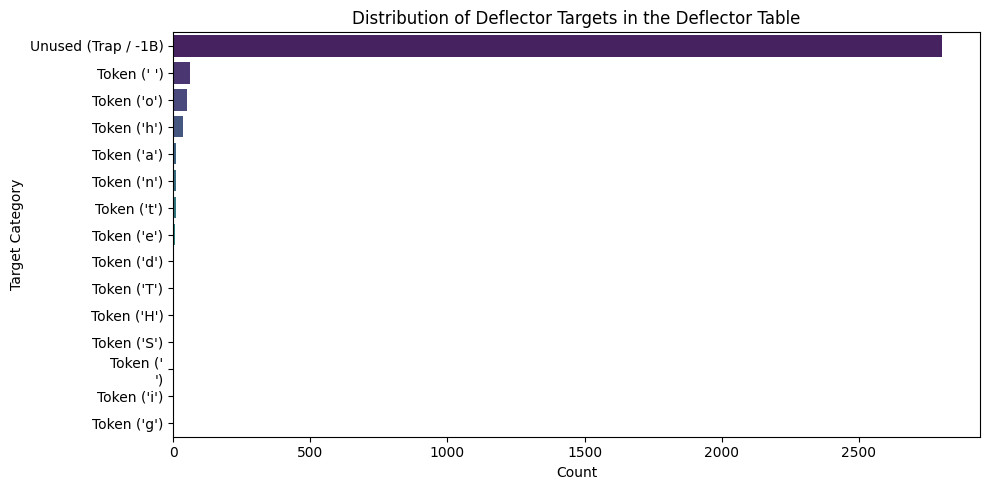

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract deflectors details: [destination, value]
deflectors = brain.deflectors_list

# Separate into values: strings (emitted symbols) vs integers (bounce energy)
target_values = []
for dest, val in deflectors:
    if isinstance(val, int):
        if val < -1e6:
            target_values.append("Unused (Trap / -1B)")
        else:
            target_values.append(f"Int Bounce ({val})")
    else:
        target_values.append(f"Token ('{val}')")

df_targets = pd.DataFrame({'Target Category': target_values})
counts = df_targets['Target Category'].value_value_counts() if hasattr(df_targets['Target Category'], 'value_value_counts') else df_targets['Target Category'].value_counts()

# Plot distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=counts.values, y=counts.index, palette='viridis')
plt.title('Distribution of Deflector Targets in the Deflector Table')
plt.xlabel('Count')
plt.ylabel('Target Category')
plt.tight_layout()
plt.show()

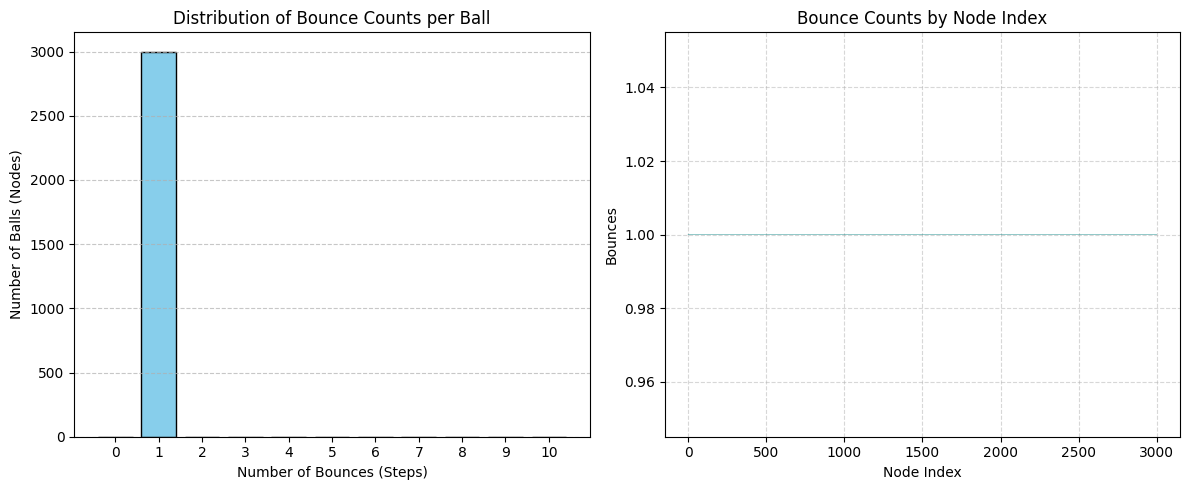

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# We will simulate a walk for each possible starting node (0 to D-1) and record the step count.
def get_bounce_counts(brain):
    step_counts = []
    dl = brain.deflectors_list
    cap = brain.cap

    for start_node in range(brain.D):
        be = brain.ball_energy
        node = start_node
        steps = 0

        while be > 0 and steps < cap:
            dest, val = dl[node]
            dist = abs(dest - node)
            if isinstance(val, int):
                be += val - dist
            else:
                be += 1 - dist
            node = dest
            steps += 1

        step_counts.append(steps)
    return step_counts

bounce_counts = get_bounce_counts(brain)

# Plot the results
plt.figure(figsize=(12, 5))

# Left subplot: Histogram of step distributions
plt.subplot(1, 2, 1)
plt.hist(bounce_counts, bins=np.arange(0, brain.cap + 2) - 0.5, rwidth=0.8, color='skyblue', edgecolor='black')
plt.title('Distribution of Bounce Counts per Ball')
plt.xlabel('Number of Bounces (Steps)')
plt.ylabel('Number of Balls (Nodes)')
plt.xticks(range(0, brain.cap + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Right subplot: Sequence plot across all D nodes
plt.subplot(1, 2, 2)
plt.plot(bounce_counts, color='teal', alpha=0.6, linewidth=0.5)
plt.title('Bounce Counts by Node Index')
plt.xlabel('Node Index')
plt.ylabel('Bounces')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Notes and limits

* **What changed.** The original global hash was an associative-memory address. The new
  address is a reusable local feature hash: the same `(relative position, token)` feature
  is shared across all examples, and each ball position has its own bucket region.
* **Why this can generalize.** A test context does not need to reproduce an entire training
  context. It only needs the relevant local features to land in buckets whose table entries
  were learned from other examples.
* **What did not change.** There is still exactly one lookup per ball. The walk never reads
  another input token after hashing, so this is not the proposed layered architecture.
* **Training objective.** Class purity / profiled CE remains primary. Reuse is only a
  tie-breaker, which prevents the optimizer from sacrificing fit merely to get more sharing.
* **Capacity knob.** `local_D` controls buckets per slot. Smaller values put more pressure
  on feature reuse; larger values make the search closer to memorization.
* **Locality knob.** `hash_radius` controls how much context a ball can use. Increasing it
  raises expressive power but weakens the inductive bias toward reuse.
